## Chargement

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/wfp_food_prices_tgo.csv", skiprows=[1])  # skiprows : ligne HXL
df["date"] = pd.to_datetime(df["date"])
df["price"] = pd.to_numeric(df["price"], errors="coerce")

print(df.shape)
print(df["date"].min(), "→", df["date"].max())
print(df.columns.tolist())
df.head()

(48725, 16)
2001-01-15 00:00:00 → 2026-09-15 00:00:00
['date', 'admin1', 'admin2', 'market', 'market_id', 'latitude', 'longitude', 'category', 'commodity', 'commodity_id', 'unit', 'priceflag', 'pricetype', 'currency', 'price', 'usdprice']


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2001-01-15,Kara,Kozah,Kara,2664,9.55,1.19,cereals and tubers,Maize (white),67,KG,actual,Retail,XOF,70.0,0.17
1,2001-01-15,Kara,Kozah,Kara,2664,9.55,1.19,cereals and tubers,Rice (imported),64,KG,actual,Retail,XOF,313.0,0.74
2,2001-01-15,Kara,Kozah,Kara,2664,9.55,1.19,cereals and tubers,Sorghum,65,KG,actual,Retail,XOF,80.0,0.19
3,2001-01-15,Maritime,Golfe,Lomé,2662,6.12,1.23,cereals and tubers,Cassava meal (gari),403,KG,actual,Retail,XOF,257.0,0.61
4,2001-01-15,Maritime,Golfe,Lomé,2662,6.12,1.23,cereals and tubers,Maize (white),67,KG,actual,Retail,XOF,106.0,0.25


## Qualité de base

In [2]:
print(df.isna().sum())                       # valeurs manquantes par colonne
print(df.duplicated(["date", "market", "commodity", "unit"]).sum(), "doublons")
print(df["pricetype"].value_counts())        # retail / wholesale
print(df["unit"].value_counts())             # unités (KG, sac...)
print(df["currency"].value_counts())          # devises

date            0
admin1          0
admin2          0
market          0
market_id       0
latitude        0
longitude       0
category        0
commodity       0
commodity_id    0
unit            0
priceflag       0
pricetype       0
currency        0
price           0
usdprice        0
dtype: int64
0 doublons
pricetype
Retail    48725
Name: count, dtype: int64
unit
KG    48725
Name: count, dtype: int64
currency
XOF    48725
Name: count, dtype: int64


## Couverture par (marché,produit)

In [3]:
# Une ligne par couple (marché, produit)
cov = (df.groupby(["market", "commodity"])
         .agg(debut=("date", "min"), fin=("date", "max"), n=("price", "size"))
         .assign(mois_possibles=lambda d: ((d.fin - d.debut).dt.days / 30.4).round() + 1)
         .assign(taux=lambda d: (d.n / d.mois_possibles).round(2)))

print("Nombre de séries (marché, produit) :", len(cov))

# Résumé par produit : combien de séries "exploitables"
bon = cov[(cov.n >= 60) & (cov.taux >= 0.7)]      # au moins 60 obs et remplie à 70 %
print(bon.groupby("commodity").size().sort_values(ascending=False))

# Les 10 meilleures séries
print(cov.sort_values("n", ascending=False).head(10))

# Observations par année (pour voir quand les données deviennent denses)
print(df.groupby(df["date"].dt.year).size())

# Vérif des types et unités
print(df["pricetype"].value_counts())
print(df.groupby("commodity")["unit"].unique())

Nombre de séries (marché, produit) : 851
commodity
Cassava meal (gari)    43
Maize (white)          41
Sorghum (red)          38
Beans (red)            38
Millet                 38
Rice (local)           38
Beans (white)          37
Soybeans               36
Rice (imported)         6
Sorghum                 5
dtype: int64
                                   debut        fin    n  mois_possibles  taux
market    commodity                                                           
Korbongou Maize (white)       2001-01-15 2026-09-15  263           309.0  0.85
Anie      Maize (white)       2001-01-15 2026-09-15  261           309.0  0.84
Cinkassé  Cassava meal (gari) 2001-01-15 2026-09-15  259           309.0  0.84
          Maize (white)       2001-01-15 2026-09-15  259           309.0  0.84
Korbongou Cassava meal (gari) 2001-01-15 2026-09-15  258           309.0  0.83
Amegnran  Cassava meal (gari) 2001-01-15 2022-06-15  257           258.0  1.00
Kara      Sorghum             2001-01-15 202

In [4]:
# 1. Séries encore actives (dernière obs. en 2026)
cov["active"] = cov["fin"] >= "2026-01-01"
print(cov["active"].value_counts())
print(cov[cov.active].groupby("commodity").size().sort_values(ascending=False))

# 2. Nature des valeurs : réelles ou estimées ?
print(df["priceflag"].value_counts())
print(df.groupby(df["date"].dt.year)["priceflag"].value_counts().unstack().tail(10))

# 3. Observations et marchés par année (pour repérer la cassure de 2022)
par_an = df.groupby(df["date"].dt.year).agg(obs=("price", "size"), marches=("market", "nunique"))
print(par_an)

# 4. Types de prix et unités
print(df["pricetype"].value_counts())
print(df.groupby("commodity")["unit"].unique())

active
True     834
False     17
Name: count, dtype: int64
commodity
Maize (white)          114
Beans (white)          112
Cassava meal (gari)    111
Soybeans               108
Sorghum (red)          105
Rice (local)            99
Beans (red)             98
Millet                  87
dtype: int64
priceflag
actual    48725
Name: count, dtype: int64
priceflag  actual
date             
2017         3674
2018         3780
2019         3742
2020         3760
2021         3788
2022         3668
2023         3524
2024         3521
2025         3519
2026         4733
       obs  marches
date               
2001   273        6
2002   272        6
2003   269        6
2004   273        6
2005   274        6
2006   272        6
2007   274        6
2008   273        6
2009   274        6
2010   272        6
2011   276        6
2012   272        6
2013   273        6
2014   274        6
2015  3589       41
2016  3606       41
2017  3674       42
2018  3780       43
2019  3742       43
2020  3760    

In [5]:
pd.set_option("display.max_rows", None)

par_an = df.groupby(df["date"].dt.year).agg(obs=("price", "size"), marches=("market", "nunique"))
print(par_an.to_string())

print(df["pricetype"].value_counts().to_string())
print(df.groupby("commodity")["unit"].unique().to_string())

# Taux de remplissage moyen des séries actives
act = cov[cov.active]
print(act["taux"].describe().round(2).to_string())

       obs  marches
date               
2001   273        6
2002   272        6
2003   269        6
2004   273        6
2005   274        6
2006   272        6
2007   274        6
2008   273        6
2009   274        6
2010   272        6
2011   276        6
2012   272        6
2013   273        6
2014   274        6
2015  3589       41
2016  3606       41
2017  3674       42
2018  3780       43
2019  3742       43
2020  3760       43
2021  3788       43
2022  3668       43
2023  3524       39
2024  3521       39
2025  3519       39
2026  4733      116
pricetype
Retail    48725
commodity
Beans (red)            [KG]
Beans (white)          [KG]
Cassava meal (gari)    [KG]
Maize (white)          [KG]
Millet                 [KG]
Rice (imported)        [KG]
Rice (local)           [KG]
Sorghum                [KG]
Sorghum (red)          [KG]
Soybeans               [KG]
count    834.00
mean       0.94
std        0.11
min        0.33
25%        0.94
50%        1.00
75%        1.00
max        1

## Vue d'ensemble des produits et des marchés

In [6]:
print(df.groupby("commodity")["market"].nunique().sort_values(ascending=False))
print(df.groupby("market")["commodity"].nunique().sort_values(ascending=False))

commodity
Maize (white)          117
Cassava meal (gari)    114
Beans (white)          112
Soybeans               108
Sorghum (red)          105
Rice (local)            99
Beans (red)             98
Millet                  87
Rice (imported)          6
Sorghum                  5
Name: market, dtype: int64
market
Anie                 10
Cinkassé             10
Korbongou             9
Afagnagan             8
Adétikopé             8
Adidogomé             8
ADJENGRE              8
Amou-oblo             8
Agbonou               8
Agoè Assiyéyé         8
Agou gare             8
Ahanou Kopé           8
Aleheride             8
Akoumapé              8
Akodésséwa            8
Amoussoukope          8
Bafilo                8
Bassar                8
Bangeli               8
Apéyémé               8
Assahoun              8
Agbandaoudé           8
Adéta                 8
Elavagnon (lacs)      8
Gando centre          8
Gboto Vodupé          8
Gléï                  8
Elavagnon             8
Dapaong centre

## Visualisation des trous

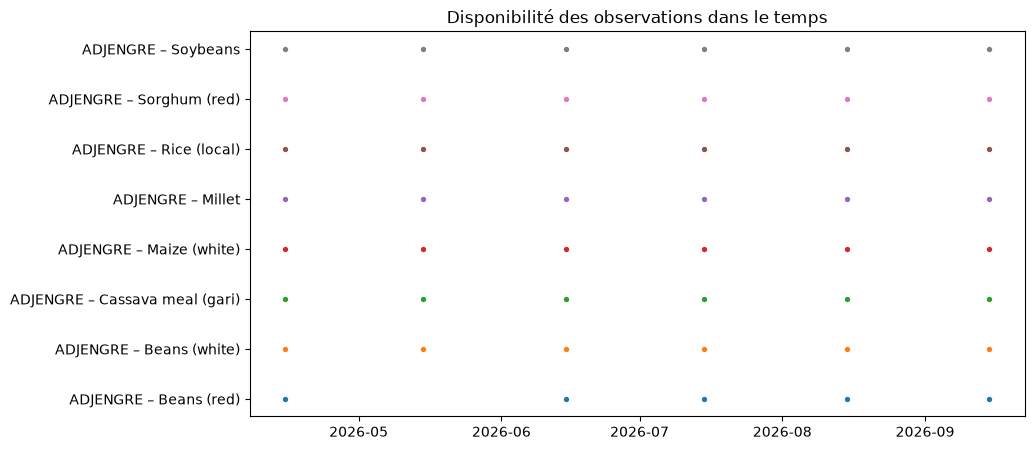

In [7]:
top = cov.head(8).index
fig, ax = plt.subplots(figsize=(10, 5))
for i, (m, c) in enumerate(top):
    d = df[(df.market == m) & (df.commodity == c)]
    ax.scatter(d["date"], [i] * len(d), s=8)
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{m} – {c}" for m, c in top])
ax.set_title("Disponibilité des observations dans le temps")
plt.show()

groupe
court (<=12 mois)    76
long (>60)           43
moyen (13-60)         0
Name: count, dtype: int64
date
2025-10-15     39
2025-11-15     39
2025-12-15     39
2026-01-15     36
2026-02-15     42
2026-03-15     42
2026-04-15    100
2026-05-15    103
2026-06-15    103
2026-07-15    105
2026-08-15    103
2026-09-15    106
Name: market, dtype: int64
count    48725.000000
mean       338.105183
std        161.272425
min         31.000000
25%        230.000000
50%        312.000000
75%        420.000000
max       2028.000000
Name: price, dtype: float64
0 prix <= 0


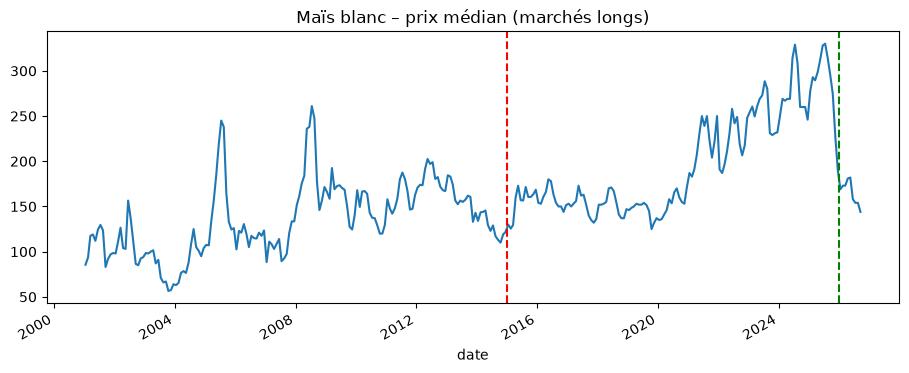

In [8]:
# 1. Historique de chaque marché
mk = (df.groupby("market")
        .agg(debut=("date", "min"), nb_mois=("date", "nunique"),
             nb_produits=("commodity", "nunique")))
mk["groupe"] = pd.cut(mk["nb_mois"], bins=[0, 12, 60, 400],
                      labels=["court (<=12 mois)", "moyen (13-60)", "long (>60)"])
print(mk["groupe"].value_counts())

# 2. Apparition des marchés en 2026, mois par mois
print(df[df["date"] >= "2025-10-01"].groupby("date")["market"].nunique())

# 3. Prix aberrants
print(df["price"].describe())
print((df["price"] <= 0).sum(), "prix <= 0")

# 4. Rupture éventuelle : prix médian du maïs sur les marchés "longs"
core = mk[mk["groupe"] == "long (>60)"].index
med = (df[(df["market"].isin(core)) & (df["commodity"] == "Maize (white)")]
         .groupby("date")["price"].median())
ax = med.plot(figsize=(11, 4), title="Maïs blanc – prix médian (marchés longs)")
ax.axvline(pd.Timestamp("2015-01-01"), ls="--", c="r")
ax.axvline(pd.Timestamp("2026-01-01"), ls="--", c="g")
plt.show()

In [9]:
cols = ["date", "market", "commodity", "price"]

# Les 10 prix les plus élevés
print(df.nlargest(10, "price")[cols].to_string())

# Rapport au prix "habituel" de la série (médiane glissante sur 5 mois, centrée)
df = df.sort_values(["market", "commodity", "date"])
df["roll"] = (df.groupby(["market", "commodity"])["price"]
                .transform(lambda s: s.rolling(5, center=True, min_periods=3).median()))
df["ratio"] = df["price"] / df["roll"]

sus = df[(df["ratio"] > 1.8) | (df["ratio"] < 0.55)]
print(len(sus), "points suspects")
print(sus.sort_values("ratio")[cols + ["roll", "ratio"]].head(10).to_string())
print(sus.sort_values("ratio")[cols + ["roll", "ratio"]].tail(10).to_string())

            date      market      commodity   price
35664 2023-08-15       Adéta  Sorghum (red)  2028.0
43332 2025-10-15        Anie  Beans (white)  1934.0
43216 2025-10-15  Akodésséwa  Beans (white)  1909.0
43311 2025-10-15     Kpalimé  Beans (white)  1848.0
43607 2025-11-15     Kpalimé  Beans (white)  1848.0
43303 2025-10-15       Adéta  Beans (white)  1828.0
43599 2025-11-15       Adéta  Beans (white)  1828.0
43897 2025-12-15       Adéta  Beans (white)  1828.0
43149 2025-10-15      Bafilo  Beans (white)  1820.0
35665 2023-08-15       Adéta    Beans (red)  1655.0
214 points suspects
            date           market      commodity  price   roll     ratio
24137 2020-07-15           Bassar    Beans (red)  125.0  656.0  0.190549
24151 2020-07-15     Guerin kouka    Beans (red)  125.0  656.0  0.190549
4837  2015-04-15      Vogan Gbeke    Beans (red)  121.0  463.0  0.261339
4845  2015-04-15          Tchékpo    Beans (red)  121.0  463.0  0.261339
31673 2022-07-15       LAMA-TESSI         M

In [10]:
import sys; sys.path.append("..")           # pour pouvoir importer src/ depuis notebooks/
from src.data.clean import load_raw, flag_outliers

d = flag_outliers(load_raw())
print(d["outlier"].sum(), "points marqués sur", len(d))
print(d[d["outlier"]].groupby(d["date"].dt.year).size().to_string())
print(d[d["outlier"]].groupby("market").size().sort_values(ascending=False).head(8))

cols = ["date", "market", "commodity", "price", "r_own", "r_cross"]
adeta = d[(d["market"] == "Adéta") & (d["commodity"] == "Sorghum (red)")
          & (d["date"].between("2023-05-01", "2023-10-31"))]
print(adeta[cols].to_string())

111 points marqués sur 45948
date
2015    30
2016     3
2017     2
2018     3
2019     4
2020    14
2021     5
2022     7
2023    17
2024     4
2025     7
2026    15
market
Adéta               13
Assahoun             7
LAMA-TESSI           6
Vogan Gbeke          6
Bombouaka centre     5
Agbonou              5
Tchékpo              5
Agbandaoudé          4
dtype: int64
            date market      commodity    price     r_own   r_cross
34777 2023-05-01  Adéta  Sorghum (red)   373.00  0.968831  0.941919
35073 2023-06-01  Adéta  Sorghum (red)   385.00  1.000000  0.935601
35369 2023-07-01  Adéta  Sorghum (red)  1650.00  3.495763  3.837209
35664 2023-08-01  Adéta  Sorghum (red)  2028.00  4.142918  4.547085
35959 2023-09-01  Adéta  Sorghum (red)   472.00  0.963265  1.072727
36257 2023-10-01  Adéta  Sorghum (red)   489.51  1.000000  1.087800


In [11]:
p = pd.read_csv("../data/processed/panel_long.csv", parse_dates=["date"]).sort_values(["market", "commodity", "date"])
p["identique"] = p.groupby(["market", "commodity"])["price"].diff() == 0
print(p.groupby(p["date"].dt.year)["identique"].mean().round(2).to_string())

date
2001    0.02
2002    0.01
2003    0.06
2004    0.03
2005    0.03
2006    0.02
2007    0.08
2008    0.06
2009    0.02
2010    0.04
2011    0.02
2012    0.06
2013    0.09
2014    0.11
2015    0.11
2016    0.08
2017    0.08
2018    0.08
2019    0.14
2020    0.09
2021    0.26
2022    0.15
2023    0.26
2024    0.45
2025    0.11
2026    0.19


In [12]:
p = (pd.read_csv("../data/processed/panel_long_brut.csv", parse_dates=["date"])
       .sort_values(["market", "commodity", "date"]))
p["fige"] = (p.groupby(["market", "commodity"])["price"].diff() == 0) & ~p["imputed"]
p24 = p[p["date"].dt.year == 2024]

print(p24.groupby("commodity")["fige"].mean().round(2).to_string())
print(p24.groupby("market")["fige"].mean().round(2).sort_values(ascending=False).head(10).to_string())
print(p24.groupby("date")["fige"].mean().round(2).to_string())


commodity
Beans (red)            0.47
Beans (white)          0.37
Cassava meal (gari)    0.49
Maize (white)          0.37
Millet                 0.52
Rice (local)           0.52
Sorghum (red)          0.39
Soybeans               0.40
market
Afagnagan           0.73
Mandouri centre     0.68
Ogaro centre        0.67
Bombouaka centre    0.61
Zogbegan            0.59
Dapaong centre      0.56
PAGALA-GARE         0.56
Cinkassé            0.55
Mango centre        0.54
Gando centre        0.53
date
2024-01-01    0.24
2024-02-01    0.24
2024-03-01    0.28
2024-04-01    0.26
2024-05-01    0.90
2024-06-01    0.24
2024-07-01    0.31
2024-08-01    0.47
2024-09-01    0.58
2024-10-01    0.80
2024-11-01    0.96
2024-12-01    0.02


In [13]:
p = (pd.read_csv("../data/processed/panel_long_brut.csv", parse_dates=["date"])
       .sort_values(["market", "commodity", "date"]))
p["fige"] = (p.groupby(["market", "commodity"])["price"].diff() == 0) & ~p["imputed"]
p24 = p[p["date"].dt.year == 2024]

print(p24.groupby("commodity")["fige"].mean().round(2).to_string())
print(p24.groupby("market")["fige"].mean().round(2).sort_values(ascending=False).head(10).to_string())
print(p24.groupby("date")["fige"].mean().round(2).to_string())

commodity
Beans (red)            0.47
Beans (white)          0.37
Cassava meal (gari)    0.49
Maize (white)          0.37
Millet                 0.52
Rice (local)           0.52
Sorghum (red)          0.39
Soybeans               0.40
market
Afagnagan           0.73
Mandouri centre     0.68
Ogaro centre        0.67
Bombouaka centre    0.61
Zogbegan            0.59
Dapaong centre      0.56
PAGALA-GARE         0.56
Cinkassé            0.55
Mango centre        0.54
Gando centre        0.53
date
2024-01-01    0.24
2024-02-01    0.24
2024-03-01    0.28
2024-04-01    0.26
2024-05-01    0.90
2024-06-01    0.24
2024-07-01    0.31
2024-08-01    0.47
2024-09-01    0.58
2024-10-01    0.80
2024-11-01    0.96
2024-12-01    0.02


In [14]:
m = p.groupby("date")["fige"].mean()
print(m[m > 0.5].round(2).to_string())

date
2023-11-01    0.54
2023-12-01    0.62
2024-05-01    0.90
2024-09-01    0.58
2024-10-01    0.80
2024-11-01    0.96
